# 01 · Data Exploration and Arabic Preprocessing
*Arabic Aspect-Based Sentiment Analysis of Hotel Reviews*

This notebook prepares the data used by the rest of the project:
1. Load the SemEval-2016 Task 5 Arabic hotel reviews (Pontiki et al., 2016) from Hugging Face.
2. Explore the data: size, class balance, aspect categories, implicit aspects, text noise, duplicates,
   conflicting labels and train/test overlap.
3. Build two preprocessing pipelines:
   * **light**, for the transformer models: removes noise but keeps the wording and context;
   * **full**, for TF-IDF: light cleaning plus letter normalisation, with optional stopword removal and stemming.
4. Hold out a validation set grouped by sentence, so no sentence appears in both training and validation.
5. Save the cleaned files and figures to Google Drive for notebooks 02–04.

In [1]:
# Set up paths: in Colab everything is saved to Google Drive so results survive a disconnect.
import os, sys, re, json, random, subprocess, unicodedata
from collections import Counter

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/MAAI902_ABSA"
else:
    BASE = "./MAAI902_ABSA"

DATA_DIR, FIG_DIR, RES_DIR = (os.path.join(BASE, d) for d in ("data", "figures", "results"))
for d in (DATA_DIR, FIG_DIR, RES_DIR):
    os.makedirs(d, exist_ok=True)

SEED = 42
random.seed(SEED)
print("Saving everything under:", BASE)

Mounted at /content/drive
Saving everything under: /content/drive/MyDrive/MAAI902_ABSA


In [2]:
# Install the Hugging Face datasets library (Colab only) and set a consistent plot style.
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets"], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"positive": "#2E7D32", "negative": "#C62828", "neutral": "#9E9E9E"}

## 1. Load the dataset
Source: `srinivasbilla/semeval-2016-absa-reviews-arabic` (MIT licence), a tabular copy of the original
SemEval-2016 Task 5 Arabic hotels data. Each row is one opinion: `sentence`, `aspect` (the opinion target,
empty when the aspect is implicit), `sentiment` and `category` (ENTITY#ATTRIBUTE).

In [3]:
# Download the train and test splits from Hugging Face.
from datasets import load_dataset
ds = load_dataset("srinivasbilla/semeval-2016-absa-reviews-arabic")
train_raw, test_raw = ds["train"].to_pandas(), ds["test"].to_pandas()

print("train:", train_raw.shape, " test:", test_raw.shape)
train_raw.head()

README.md:   0%|          | 0.00/594 [00:00<?, ?B/s]

hotel_review_absa_arabic_train.csv:   0%|          | 0.00/3.02M [00:00<?, ?B/s]

hotel_review_absa_arabic_test.csv:   0%|          | 0.00/731k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/10509 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2604 [00:00<?, ? examples/s]

train: (10509, 4)  test: (2604, 4)


,sentence,aspect,sentiment,category
0,أنصح بالنوم وليس تناول الطعام موقع مثالي للإق...,موقع,positive,LOCATION#GENERAL
1,كانت الغرفة ممتازة وكذلك الموظفون وبوفيه الإفط...,الغرفة,positive,ROOMS#GENERAL
2,كانت الغرفة ممتازة وكذلك الموظفون وبوفيه الإفط...,الموظفون,positive,SERVICE#GENERAL
3,كانت الغرفة ممتازة وكذلك الموظفون وبوفيه الإفط...,بوفيه الإفطار,positive,FOOD_DRINKS#QUALITY
4,كانت الغرفة ممتازة وكذلك الموظفون وبوفيه الإفط...,وجبة العشاء,negative,FOOD_DRINKS#PRICES


## 2. Exploratory analysis

In [4]:
# Size, class balance, implicit aspects and number of categories for each split.
def describe(df, name):
    s = df["sentiment"].value_counts()
    print(f"--- {name}: {len(df):,} aspect rows, {df['sentence'].nunique():,} unique sentences")
    for k, v in s.items():
        print(f"   {k:<9}{v:>6}  ({v/len(df):.1%})")
    print(f"   implicit aspects (aspect = null): {df['aspect'].isna().sum():,} ({df['aspect'].isna().mean():.1%})")
    print(f"   distinct categories: {df['category'].nunique()}")

describe(train_raw, "TRAIN"); describe(test_raw, "TEST")

imbalance_ratio = train_raw["sentiment"].value_counts().max() / train_raw["sentiment"].value_counts().min()
print(f"\nImbalance ratio (majority/minority) in train: {imbalance_ratio:.2f}")

--- TRAIN: 10,509 aspect rows, 4,776 unique sentences
   positive   6197  (59.0%)
   negative   3629  (34.5%)
   neutral     683  (6.5%)
   implicit aspects (aspect = null): 889 (8.5%)
   distinct categories: 34
--- TEST: 2,604 aspect rows, 1,225 unique sentences
   positive   1508  (57.9%)
   negative    927  (35.6%)
   neutral     169  (6.5%)
   implicit aspects (aspect = null): 232 (8.9%)
   distinct categories: 34

Imbalance ratio (majority/minority) in train: 9.07


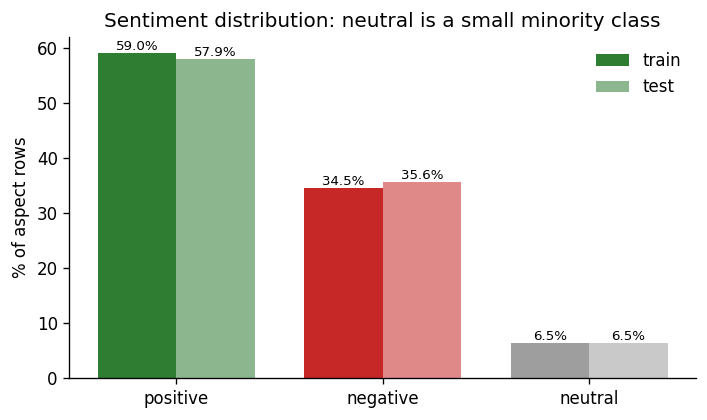

In [5]:
# Sentiment distribution in train and test: neutral opinions are a small minority.
fig, ax = plt.subplots(figsize=(6, 3.6))
order = ["positive", "negative", "neutral"]
x = np.arange(len(order)); w = 0.38
for i, (df, lab) in enumerate([(train_raw, "train"), (test_raw, "test")]):
    pct = df["sentiment"].value_counts(normalize=True).reindex(order).fillna(0) * 100
    bars = ax.bar(x + (i - .5) * w, pct, w, label=lab, color=[COLORS[o] for o in order], alpha=1 if i == 0 else .55)
    ax.bar_label(bars, fmt="%.1f%%", fontsize=8)
ax.set_xticks(x, order); ax.set_ylabel("% of aspect rows"); ax.legend(frameon=False)
ax.set_title("Sentiment distribution: neutral is a small minority class")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig1_sentiment_distribution.png", bbox_inches="tight"); plt.show()

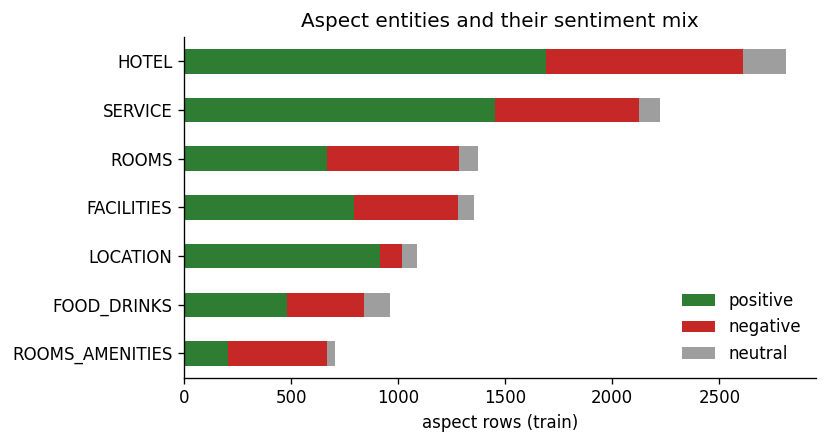

sentiment,positive,negative,neutral
entity,,,
ROOMS_AMENITIES,203,466,36
FOOD_DRINKS,479,361,120
LOCATION,913,107,67
FACILITIES,792,487,75
ROOMS,669,615,87
SERVICE,1452,672,97
HOTEL,1689,921,201


In [6]:
# Group the 34 ENTITY#ATTRIBUTE categories into 7 entities and plot the sentiment mix of each.
def entity_of(cat):  return cat.split("#")[0]
def cat_text(cat):   return cat.replace("#", " ").replace("_", " ").lower()   # ROOMS#CLEANLINESS -> "rooms cleanliness"

for df in (train_raw, test_raw):
    df["entity"] = df["category"].map(entity_of)

ent = (train_raw.groupby(["entity", "sentiment"]).size().unstack(fill_value=0)[order])
ent = ent.loc[ent.sum(axis=1).sort_values().index]
ax = ent.plot.barh(stacked=True, color=[COLORS[o] for o in order], figsize=(7, 3.8))
ax.set_xlabel("aspect rows (train)"); ax.set_ylabel("")
ax.set_title("Aspect entities and their sentiment mix")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig2_entities.png", bbox_inches="tight"); plt.show()
ent

In [7]:
# How noisy is the text? Share of unique sentences containing each kind of noise, plus sentence length.
AR_DIAC = re.compile(r"[ؗ-ًؚ-ْٰ]")
TATWEEL = "ـ"
REPEAT = re.compile(r"(.)\1{2,}")
URL = re.compile(r"https?://\S+|www\.\S+")
LATIN = re.compile(r"[A-Za-z]")
DIGIT = re.compile(r"[0-9٠-٩]")
EMOJI = re.compile(r"[\U0001F300-\U0001FAFF☀-➿]")

uniq = pd.Series(pd.concat([train_raw["sentence"], test_raw["sentence"]]).unique()).astype(object)

def rate(pattern):
    """Share of unique sentences matching a regex (works across pandas versions)."""
    rx = re.compile(pattern) if isinstance(pattern, str) else pattern
    return uniq.apply(lambda s: bool(rx.search(s))).mean()

noise = {
    "diacritics (tashkeel)": rate(AR_DIAC),
    "tatweel (ـ)": rate(TATWEEL),
    "repeated letters (3+)": rate(REPEAT),
    "URLs": rate(URL),
    "Latin characters": rate(LATIN),
    "digits": rate(DIGIT),
    "emoji": rate(EMOJI),
    "alef variants (أ إ آ)": rate("[أإآ]"),
    "taa marbuta (ة)": rate("ة"),
    "alef maqsura (ى)": rate("ى"),
}
noise_df = (pd.Series(noise) * 100).round(1).rename("% of unique sentences").to_frame()
lens = uniq.str.split().str.len()
print(f"Words per sentence: mean {lens.mean():.1f}, median {lens.median():.0f}, 95th pct {lens.quantile(.95):.0f}, max {lens.max()}")
noise_df

Words per sentence: mean 20.8, median 18, 95th pct 51, max 84


,% of unique sentences
diacritics (tashkeel),24.4
tatweel (ـ),0.4
repeated letters (3+),6.7
URLs,0.0
Latin characters,1.6
digits,13.0
emoji,0.0
alef variants (أ إ آ),58.6
taa marbuta (ة),78.7
alef maqsura (ى),44.2


In [8]:
# Data-quality checks: exact duplicates, the same (sentence, category) with different labels, and train/test overlap.
dup_rows = train_raw.duplicated(["sentence", "category", "sentiment"]).sum()
conf = (train_raw.groupby(["sentence", "category"])["sentiment"].nunique() > 1).sum()
overlap = len(set(train_raw["sentence"]) & set(test_raw["sentence"]))
quality = {
    "exact duplicate rows (sentence, category, sentiment) in train": int(dup_rows),
    "(sentence, category) pairs with CONFLICTING sentiment in train": int(conf),
    "sentences appearing in both train and test": int(overlap),
    "avg aspect rows per sentence (train)": round(len(train_raw) / train_raw["sentence"].nunique(), 2),
}
pd.Series(quality, name="count").to_frame()

,count
"exact duplicate rows (sentence, category, sentiment) in train",1330.0
"(sentence, category) pairs with CONFLICTING sentiment in train",94.0
sentences appearing in both train and test,5.0
avg aspect rows per sentence (train),2.2


In [9]:
# Contrast words such as "but" often mix two opinions in one sentence, a known source of errors (Alyami et al., 2025).
CONTRAST = ["لكن", "ولكن", "بس", "الا ان", "إلا أن", "الا انه", "رغم", "بالرغم", "مع ذلك", "ومع ذلك"]
has_contrast = uniq.apply(lambda s: any(c in s for c in CONTRAST))
print(f"Sentences with a contrast marker: {has_contrast.mean():.1%}")

Sentences with a contrast marker: 20.5%


## 3. Preprocessing pipelines
The two model families need different input, so there are two levels of cleaning:

| Step | light (AraBERT / CAMeLBERT / LLM) | full (TF-IDF) |
|---|---|---|
| Unicode NFKC, URLs → `رابط`, emoji removed | ✓ | ✓ |
| Remove diacritics & tatweel | ✓ | ✓ |
| Collapse letter repetition (رائعععع → رائعع) | ✓ | ✓ |
| Normalise أ/إ/آ→ا, ى→ي, ة→ه, ؤ→و, ئ→ي | – (pretrained vocab expects them) | ✓ |
| Remove punctuation, digits, Latin | – | ✓ |
| Stopword removal / ISRI light stemming | – (destroys context, e.g. negation) | optional (ablation in 02) |

In [10]:
# Stopword list for the optional TF-IDF ablation. Negation words are removed from it because they flip the sentiment.
AR_STOPWORDS = set("""
في من على إلى الى عن مع هذا هذه ذلك تلك هناك هنا التي الذي الذين اللذين ان أن إن او أو ثم كل كان كانت يكون
تكون قد لقد كما ايضا أيضا حيث عند عندما بعد قبل بين حتى اذا إذا لو ما ماذا كيف اين أين هو هي هم هن انا أنا نحن
انت أنت انتم الي التى اي أي بعض غير منذ خلال لدى لدي له لها لهم به بها فيه فيها منه منها عليه عليها اليه إليه
وكان وكانت وفي ومن وعلى وهو وهي وهذا وهذه فقط جدا جداً يا ف و ب ل ك
""".split())
NEGATIONS = {"لا", "لم", "لن", "ليس", "ليست", "مو", "مش", "ما", "غير", "بدون"}
AR_STOPWORDS -= NEGATIONS

def light_clean(text: str) -> str:
    """Remove noise but keep the original wording (used for the transformers and the LLM)."""
    t = unicodedata.normalize("NFKC", str(text))
    t = URL.sub(" رابط ", t)
    t = EMOJI.sub(" ", t)
    t = AR_DIAC.sub("", t).replace(TATWEEL, "")
    t = REPEAT.sub(r"\1\1", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

def normalize_letters(t: str) -> str:
    """Merge spelling variants of the same letter so TF-IDF sees one form."""
    t = re.sub("[أإآٱ]", "ا", t)
    return t.replace("ى", "ي").replace("ة", "ه").replace("ؤ", "و").replace("ئ", "ي")

try:
    from nltk.stem.isri import ISRIStemmer
    _stemmer = ISRIStemmer()
except Exception:
    _stemmer = None

def full_clean(text: str, remove_stopwords=False, stem=False) -> str:
    """Light cleaning + letter normalisation, Arabic letters only; stopwords and stemming are optional."""
    t = normalize_letters(light_clean(text))
    t = re.sub(r"[^ء-ي\s]", " ", t)          # keep Arabic letters only
    toks = t.split()
    if remove_stopwords:
        toks = [w for w in toks if w not in AR_STOPWORDS]
    if stem and _stemmer is not None:
        toks = [_stemmer.stem(w) for w in toks]
    return " ".join(toks)

# Side-by-side view of what each cleaning level does, on short sentences that contain diacritics,
# tatweel or repeated letters, so the effect of cleaning is visible.
showcase = uniq[uniq.apply(lambda s: bool(AR_DIAC.search(s) or REPEAT.search(s) or TATWEEL in s))]
showcase = showcase[showcase.str.len() < 90]
examples = showcase.sample(min(6, len(showcase)), random_state=SEED).tolist()
pd.DataFrame({
    "original": examples,
    "light (transformers)": [light_clean(s) for s in examples],
    "full (TF-IDF)": [full_clean(s) for s in examples],
    "full + stopwords + stem": [full_clean(s, True, True) for s in examples],
})

,original,light (transformers),full (TF-IDF),full + stopwords + stem
0,لطيف جدًا الفندق رائع... الردهة تجعلك تشعر وكأ...,لطيف جدا الفندق رائع.. الردهة تجعلك تشعر وكأنك...,لطيف جدا الفندق رايع الردهه تجعلك تشعر وكانك ف...,لطف ندق ريع رده جعل شعر وكن هوء طلق بمد استواييه
1,فريق العمل مهذب جدًا ومحترف، والخدمة ممتازة.,فريق العمل مهذب جدا ومحترف، والخدمة ممتازة.,فريق العمل مهذب جدا ومحترف والخدمه ممتازه,فرق عمل هذب حرف خدم متز
2,فريق عمل ودود يقدم وجبة إفطار سيئة للغاية. كن ...,فريق عمل ودود يقدم وجبة إفطار سيئة للغاية. كن ...,فريق عمل ودود يقدم وجبه افطار سييه للغايه كن حذرا,فرق عمل ودد قدم وجب فطر سيه غيه كن حذر
3,هذا الفندق قديم ويحتاج إلى تجديد كامل. ومع ذلك...,هذا الفندق قديم ويحتاج إلى تجديد كامل. ومع ذلك...,هذا الفندق قديم ويحتاج الي تجديد كامل ومع ذلك ...,ندق قدم حاج جدد كمل ومع فهو كلف
4,موظف وحيد على الإستقبال ... لا حامل للشنط ...,موظف وحيد على الإستقبال .. لا حامل للشنط ..,موظف وحيد علي الاستقبال لا حامل للشنط,وظف وحد علي قبل لا حمل شنط
5,كما ان نوعية الاكل كانت قليلة جداً,كما ان نوعية الاكل كانت قليلة جدا,كما ان نوعيه الاكل كانت قليله جدا,نوع اكل قلل


In [11]:
# Quick checks that the cleaning functions behave as described above.
assert light_clean("جمـــيل") == "جميل"
assert light_clean("رائعععع") == "رائعع"
assert light_clean("نوعيّة") == "نوعية"
assert normalize_letters("أإآ ى ة") == "ااا ي ه"
assert "لا" in full_clean("لا يوجد انترنت", remove_stopwords=True).split()   # negation kept
print("Preprocessing tests passed ✓")

Preprocessing tests passed ✓


## 4. Final tables and a leakage-free validation split
The original data only has train and test. 15% of the training **sentences** (not rows) are held out for
validation, because one sentence appears in several rows (one per aspect); splitting by row would leak
sentences into the validation set.

In [12]:
# Add the cleaned text columns, remove exact duplicates, split by sentence and save train/val/test.
from sklearn.model_selection import GroupShuffleSplit

def prepare(df):
    out = df.copy()
    out["aspect"] = out["aspect"].fillna("NULL")
    out["implicit"] = out["aspect"].eq("NULL")
    out["category_text"] = out["category"].map(cat_text)
    out["text_light"] = out["sentence"].map(light_clean)
    out["text_full"] = out["sentence"].map(full_clean)
    out["text_full_sw"] = out["sentence"].map(lambda s: full_clean(s, remove_stopwords=True))
    out["text_full_sw_stem"] = out["sentence"].map(lambda s: full_clean(s, True, True))
    out["has_contrast"] = out["sentence"].apply(lambda s: any(c in s for c in CONTRAST))
    out["n_words"] = out["sentence"].str.split().str.len()
    return out

train_all, test = prepare(train_raw), prepare(test_raw)
train_all = train_all.drop_duplicates(["sentence", "category", "sentiment"]).reset_index(drop=True)

gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
tr_idx, va_idx = next(gss.split(train_all, groups=train_all["sentence"]))
train, val = train_all.iloc[tr_idx].reset_index(drop=True), train_all.iloc[va_idx].reset_index(drop=True)
assert not set(train["sentence"]) & set(val["sentence"]), "leakage!"

test["row_id"] = np.arange(len(test))       # stable id so later notebooks can join their predictions
for name, df in [("train", train), ("val", val), ("test", test)]:
    df.to_csv(f"{DATA_DIR}/{name}.csv", index=False)
    print(f"{name:<5} {len(df):>6} rows | " + " ".join(f"{k}={v}" for k, v in df['sentiment'].value_counts().items()))

train   7787 rows | positive=4540 negative=2704 neutral=543
val     1392 rows | positive=776 negative=505 neutral=111
test    2604 rows | positive=1508 negative=927 neutral=169


In [13]:
# Save the key statistics of the data audit.
summary = {
    "train_rows_raw": int(len(train_raw)), "test_rows": int(len(test_raw)),
    "train_rows_after_dedup": int(len(train_all)), "train_rows": int(len(train)), "val_rows": int(len(val)),
    "unique_sentences_total": int(len(uniq)), "imbalance_ratio_train": round(float(imbalance_ratio), 2),
    "implicit_rate_train": round(float(train_raw['aspect'].isna().mean()), 4),
    "n_categories": int(train_raw["category"].nunique()),
    "class_pct_train": {k: round(float(v) * 100, 1) for k, v in train_all["sentiment"].value_counts(normalize=True).items()},
    "class_pct_test": {k: round(float(v) * 100, 1) for k, v in test["sentiment"].value_counts(normalize=True).items()},
    "noise_pct": noise_df.iloc[:, 0].to_dict(), "quality_checks": quality,
    "contrast_marker_rate": round(float(has_contrast.mean()), 4),
    "words_per_sentence": {"mean": round(float(lens.mean()), 1), "median": float(lens.median()), "max": int(lens.max())},
}
with open(f"{RES_DIR}/01_data_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
print(json.dumps(summary, ensure_ascii=False, indent=2))

{
  "train_rows_raw": 10509,
  "test_rows": 2604,
  "train_rows_after_dedup": 9179,
  "train_rows": 7787,
  "val_rows": 1392,
  "unique_sentences_total": 5996,
  "imbalance_ratio_train": 9.07,
  "implicit_rate_train": 0.0846,
  "n_categories": 34,
  "class_pct_train": {
    "positive": 57.9,
    "negative": 35.0,
    "neutral": 7.1
  },
  "class_pct_test": {
    "positive": 57.9,
    "negative": 35.6,
    "neutral": 6.5
  },
  "noise_pct": {
    "diacritics (tashkeel)": 24.4,
    "tatweel (ـ)": 0.4,
    "repeated letters (3+)": 6.7,
    "URLs": 0.0,
    "Latin characters": 1.6,
    "digits": 13.0,
    "emoji": 0.0,
    "alef variants (أ إ آ)": 58.6,
    "taa marbuta (ة)": 78.7,
    "alef maqsura (ى)": 44.2
  },
  "quality_checks": {
    "exact duplicate rows (sentence, category, sentiment) in train": 1330,
    "(sentence, category) pairs with CONFLICTING sentiment in train": 94,
    "sentences appearing in both train and test": 5,
    "avg aspect rows per sentence (train)": 2.2
  },
  